In [48]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

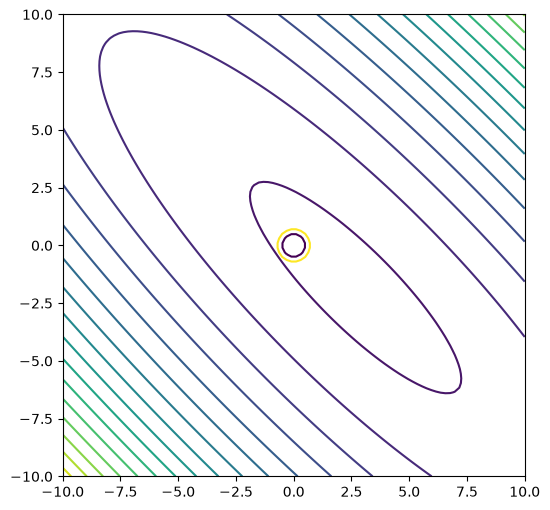

In [ ]:
x = np.linspace(-10,10,100)
y = np.linspace(-10,10,100)

data = pd.read_csv("/Volumes/DEV/OVTK/ML-fromscratch-sklearn/testing/Linear Regression 2 Features.csv")
X_data = np.array(data[["x1", "x2"]])
y_data = np.array(data["y"])

z = np.zeros((x.shape[0], y.shape[0]))
for i in range(x.shape[0]):
    for j in range(y.shape[0]):
        w = np.array([x[i], y[j]])
        y_hat = X_data @ w - y_data
        z[j][i] = (1/X_data.shape[0] * (y_hat.T @ y_hat))

x1 = np.linspace(-5,5,100)
y1 = np.linspace(-5,5,100)
z1 = np.zeros((x.shape[0], y.shape[0]))
for i in range(x.shape[0]):
    for j in range(y.shape[0]):
        z1[j][i] = x[i] ** 2 + y[j] ** 2
fig, ax = plt.subplots(figsize=(8, 6))

ax.contour(x, y, z,  levels=20)
ax.contour(x, y, z1, levels = [0.25, 0.5], )
ax.set_aspect("equal")

plt.show()

In [37]:
import pandas as pd

In [ ]:
data = pd.read_csv("/Volumes/DEV/OVTK/ML-fromscratch-sklearn/testing/Linear Regression 2 Features.csv")
X_data = np.array(data[["x1", "x2"]])
y_data = np.array(data["y"])


[4.02646697 1.57419886 5.02670346 4.46886954 3.57634819 2.41339661
 4.85913405 4.89042524 4.247129   2.94351127 3.8862659  5.50626866
 3.88296681 5.96213705 4.77544898 2.14411256 4.24568715 2.01534577
 5.17155081 4.88519408 3.99635242 2.76213119 5.16451643 4.3897781
 3.18508599 3.28897072 2.64498429 3.23253014 4.89357406 4.86572708
 7.5856403  4.14594269 3.077399   1.51450745 5.60685011 5.77378822
 5.60175117 2.86618299 3.77324313 5.34923855 5.60902342 4.81612681
 4.8242209  5.8876994  2.19809184 5.01556085 6.26867564 2.58405853
 2.56076554 5.19828727 4.63519089 4.54697862 1.23212249 4.99596173
 3.66672637 2.59572704 3.55986906 5.91043958 3.16093441 6.35407469
 2.26666838 3.62202699 3.59551079 4.66934398 4.16304811 3.95448268
 3.37273187 3.62283151 5.25972964 3.52983846 3.18514324 2.26237248
 2.91037879 2.81814248 2.95408466 4.40739458 4.41847756 4.87454091
 3.71387889 4.04914312 4.18532091 5.0848873  2.77869331 3.29095433
 3.51884765 4.95283088 3.01194326 4.07682879 4.61872063 4.79245

In [27]:
a = np.array([1,2,3])
b = np.array([4,5,6])
print(a.shape, b.shape)

(3,) (3,)


In [ ]:
def softmax_loss_naive(W, X, y, reg):
    """
    Softmax loss function, naive implementation (with loops)

    Inputs have dimension D, there are C classes, and we operate on minibatches
    of N examples.

    Inputs:
    - W: A numpy array of shape (D, C) containing weights.
    - X: A numpy array of shape (N, D) containing a minibatch of data.
    - y: A numpy array of shape (N,) containing training labels; y[i] = c means
      that X[i] has label c, where 0 <= c < C.
    - reg: (float) regularization strength

    Returns a tuple of:
    - loss as single float
    - gradient with respect to weights W; an array of same shape as W
    """
    # Initialize the loss and gradient to zero.
    loss = 0.0
    dW = np.zeros_like(W)

    # compute the loss and the gradient
    num_classes = W.shape[1]
    num_train = X.shape[0]
    for i in range(num_train):
        scores = X[i].dot(W)

        # compute the probabilities in numerically stable way
        scores -= np.max(scores)
        p = np.exp(scores)
        p /= p.sum()  # normalize
        logp = np.log(p)

        loss -= logp[y[i]]  # negative log probability is the loss


    # normalized hinge loss plus regularization
    loss = loss / num_train + reg * np.sum(W * W)

    #############################################################################
    # TODO:                                                                     #
    # Compute the gradient of the loss function and store it dW.                #
    for i in range(num_train):
        scores = X[i].dot(W)

        scores -= np.max(scores)
        p = np.exp(scores)
        p /= p.sum()  
        p[y[i]] -= 1

        x_col = X[i].reshape(-1, 1)
        p = p.reshape(1,-1)
        dW += x_col @ p
    dW /= num_train
    dW += 2 * reg * W
X = np.array([[1,2,3], [4,5,6]])
W = np.zeros((3,4))
y = np.array([0,1])
softmax_loss_naive(W, X, y, reg = 0.1)

[[ 0.125 -1.375  0.625  0.625]
 [-0.125 -1.625  0.875  0.875]
 [-0.375 -1.875  1.125  1.125]]


In [55]:
a = np.array([[1,2,3],[4,5,6]])
b = np.array([4,5])
b = b.reshape(-1,1)
print(a-b)

[[-3 -2 -1]
 [-1  0  1]]


In [54]:
print(np.sum(a, axis = 1))
print(np.max(a, axis = 1))

[ 6 15]
[3 6]


In [ ]:
def softmax(X, W, y , reg):
    # X: (N, D), W: (D, C), y: (N, ) 
    num_samples = X.shape[0]

    score = X @ W                                           # (N,C)
    max_row_exp = np.max(score, axis = 1, keepdims = True)
    score -= max_row_exp
    score = np.exp(score)
    sum_row_exp = np.sum(score, axis = 1, keepdims = True)
    score = score / sum_row_exp
    log_score = np.log(score)

    # Compute_loss
    loss = -np.mean(log_score[np.arange(num_samples), y])                                                                                  
    loss += reg * np.sum(W ** 2)

    # Compute gradient
    score[range(num_samples), y] -= 1                       # (N,C)
    dW = 1/num_samples * X.T @ score + 2 * reg * W          # (D,C)
    return loss, dW

In [ ]:
class Loss:
    def gradient(self):
        grad_w = None
        grad_b = None
        ...
        return grad_w, grad_b
class Momentum:
    def __init__(self, loss , theta = 0.9 ,learning_rate = .01, num_iters = 100):
        self.theta = theta
        self.learning_rate = learning_rate
        self.loss = loss()
        self.num_iters = num_iters
    def train(self, X, y):
        self.w = self.b = 0
        m_t_w = m_t_b = 0
        for _ in range(self.num_iters):
            grad_w, grad_b = self.loss.gradient(X, self.w, self.b, y)
            m_t_w = self.theta * m_t_w + (1 - self.theta) * grad_w
            m_t_b = self.theta * m_t_b + (1 - self.theta) * grad_b
            self.w -= self.learning_rate * m_t_w
            self.b -= self.learning_rate * m_t_b
        return self.w, self.b
class RMSProp:
    def __init__(self, loss , beta = 0.9 ,learning_rate = .01, num_iters = 100):
            self.beta = beta
            self.learning_rate = learning_rate
            self.loss = loss()
            self.num_iters = num_iters
    def train(self, X, y):
        epsilon = 1e-6
        self.w = self.b = 0
        s_t_w = s_t_b = 0
        for _ in range(self.num_iters):
            grad_w, grad_b = self.loss.gradient(X, self.w, self.b, y)
            s_t_w = self.beta * s_t_w + (1 - self.beta) * grad_w ** 2
            s_t_b = self.beta * s_t_b + (1 - self.beta) * grad_b ** 2
            self.w -= self.learning_rate / (np.sqrt(s_t_w) + epsilon) * grad_w
            self.b -= self.learning_rate / (np.sqrt(s_t_b) + epsilon) * grad_b
        return self.w, self.b